<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🔁 ReAct 循环 + 工具拿 state：`InjectedState` → `ToolRuntime`

**一句话定位**：Agent ≠ LLM。Agent = LangGraph 跑的 **agent ⇄ tools 状态机**；LLM 只是其中一个节点，而且**无状态**。工具想用 state，只能靠框架**注入**。
> 对应主课 `0_a_🔥_create_agent.ipynb`；本机验证：langchain 1.4.6 / langgraph 1.2.16 / deepagents 0.7.28。

</div>

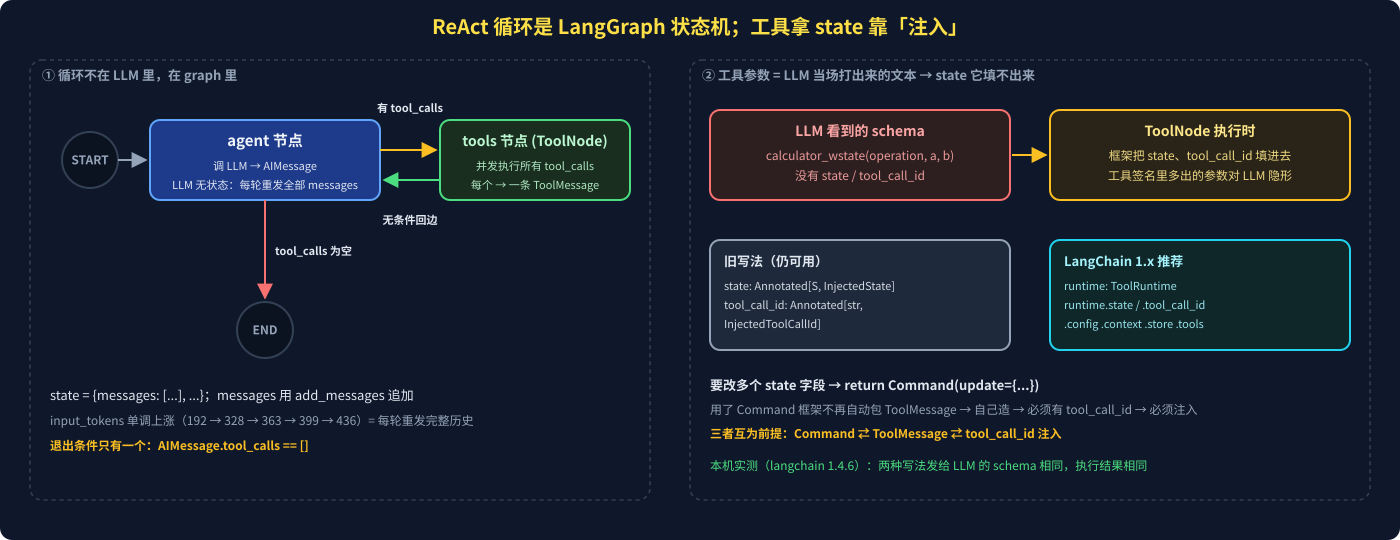

In [ ]:
from IPython.display import SVG
SVG(filename="assets/01_react_injection.svg")

### 1️⃣ ReAct = 状态机，不是「LLM 自己在循环」

| 零件 | 做什么 |
|---|---|
| `agent` 节点 | 把 **system prompt + 全部 messages + 工具描述** 发给 LLM → 得到一条 `AIMessage` |
| 条件边 | `AIMessage.tool_calls` 非空 → `tools`；为空 → `END`（唯一退出条件） |
| `tools` 节点（`ToolNode`） | **并发**执行该条 AIMessage 里的所有 tool_calls，每个产出一条 `ToolMessage(tool_call_id=…)` |
| 回边 | `tools → agent` 无条件，直接再调 LLM |

LLM **无状态**：每轮把完整 messages 重发，所以 `input_tokens` 单调上涨。`recursion_limit`（默认 25）限制总步数，`.with_config({"recursion_limit": 20})` 可调。

`create_agent(model, tools, system_prompt=…, state_schema=…)` 返回的就是这张编译好的 `CompiledStateGraph`（`langchain.agents`，1.0 起从 `langgraph.prebuilt.create_react_agent` 改名迁入）。

### 2️⃣ 工具为什么拿不到 state —— 以及两种注入写法

tool call 的**所有参数都是 LLM 当场打字打出来的**（写诗和写参数对它是同一件事）。`state` 它看不到，自然填不出。解法：把这个参数从发给 LLM 的 schema 里**剥掉**，`ToolNode` 执行时由框架**注入**。

In [ ]:
from typing import Annotated, Literal

from langchain.agents import AgentState
from langchain.tools import ToolRuntime                       # LangChain 1.x 推荐
from langchain_core.messages import ToolMessage
from langchain_core.tools import InjectedToolCallId, tool
from langgraph.prebuilt import InjectedState                 # 旧写法，1.4.6 仍可用
from langgraph.types import Command


class CalcState(AgentState):
    ops: list[str]


@tool
def calc_old(
    operation: Literal["add", "multiply"], a: float, b: float,
    state: Annotated[CalcState, InjectedState],              # 不发给 LLM
    tool_call_id: Annotated[str, InjectedToolCallId],        # 不发给 LLM
) -> Command:
    """Two-input calculator (old injection style)."""
    result = a + b if operation == "add" else a * b
    return Command(update={"ops": [f"({operation}, {a}, {b})"],
                           "messages": [ToolMessage(str(result), tool_call_id=tool_call_id)]})


@tool
def calc_new(operation: Literal["add", "multiply"], a: float, b: float, runtime: ToolRuntime) -> Command:
    """Two-input calculator (ToolRuntime style)."""
    result = a + b if operation == "add" else a * b
    return Command(update={"ops": [f"({operation}, {a}, {b})"],
                           "messages": [ToolMessage(str(result), tool_call_id=runtime.tool_call_id)]})


# LLM 看到的参数：两种写法都只剩 operation / a / b（本机实测）
print(list(calc_old.tool_call_schema.model_json_schema()["properties"]))
print(list(calc_new.tool_call_schema.model_json_schema()["properties"]))

### 3️⃣ `ToolRuntime` 一个参数拿全部

| 属性 | 对应旧注解 | 内容 |
|---|---|---|
| `runtime.state` | `InjectedState` | 当前 graph state（dict 视图） |
| `runtime.tool_call_id` | `InjectedToolCallId` | 本次调用 id，造 `ToolMessage` 必需 |
| `runtime.config` | `RunnableConfig` 注入 | thread_id 等 |
| `runtime.context` | — | `context_schema` 的运行时数据（如 user_id） |
| `runtime.store` | `InjectedStore` | 长期记忆 Store |
| `runtime.stream_writer` | `get_stream_writer()` | 自定义流（`stream_mode="custom"`） |
| `runtime.tools` | — | 本 agent 全部工具对象 |

参数名必须叫 `runtime`、类型注解必须是 `ToolRuntime`，不需要 `Annotated`。`deepagents` 的内置 `task` 工具就是 `task(description, subagent_type, runtime: ToolRuntime)`。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**三者互为前提**（最容易漏的一环）

普通 `return 值` → 框架自动包成 `ToolMessage` 并入 `messages`。
一旦要**同时改别的字段**（`ops`、`todos`、`files`）就得 `return Command(update={...})` → 框架**不再**自动包 → `messages` 里必须**自己放一条 ToolMessage** → 它必须带与请求配对的 `tool_call_id` → 所以 `tool_call_id` 也要注入。漏掉 ToolMessage 的后果：下一次调模型报「tool_call 没有响应」。

</div>

### 4️⃣ 新课视角：LLM → Agent → Deep Agent

| 层 | 是什么 | 本课位置 |
|---|---|---|
| **LLM** | 文本 → 文本，不能行动 | `init_chat_model("anthropic:claude-haiku-4-5")` |
| **Agent** | LLM + 工具循环（本笔记的状态机） | `create_agent(...)` |
| **Deep Agent** | Agent + **harness**：system prompt、文件系统、子 agent、context 管理、可选 planning | `create_deep_agent(model=model)` 一行 |

新课第一个程序只有三行：`agent = create_deep_agent(model=model)` → `agent.invoke({"messages": [...]})` → `result["messages"][-1].text`。
`.text` 取纯文本；`.content` 是原始 block 列表（Anthropic 的 thinking / text / tool_use 都在里面）。

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 工具里 `return Command(...)` 但 `messages` 没放 ToolMessage | 下一轮模型调用报错：tool_call 无响应 |
| `ToolMessage.tool_call_id` 和请求对不上 | 同上 |
| 并行 tool_calls 各自读到**同一快照**的 state | 用默认「覆盖」reducer 会丢更新 → 列表/dict 字段要配 merge reducer（见笔记 03） |
| 把 `state` 参数不加注解直接写进签名 | LLM 会尝试「编」一个 state 传进来 |
| `recursion_limit` 太小 | `GraphRecursionError`；`remaining_steps` 字段由 graph 自己维护 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：循环在 **graph** 里不在 LLM 里；LLM 填不出 `state`，所以靠 **注入**（旧：`Annotated[..., InjectedState]`，新：`runtime: ToolRuntime`）；要改多个字段就 **`Command(update=…)` + 自己造 `ToolMessage(tool_call_id=…)`**，三者互为前提。

</div>